# Denguide: A Retrieval-Augmented Chatbot for DOH Dengue Guideline Lookup in Primary Care

**AI3 Machine Project, Group 11**
Aldea, Adrian Ivan D. | Balugay, Ricci Marcelino P. | Dorosan, Jessica Danielle D.

This notebook builds and evaluates Denguide, a RAG chatbot over the DOH Clinical Practice Guideline on Dengue (2023). It compares two open-weight LLMs inside the same pipeline: **Qwen3-8B** and **Gemma 3 12B-IT**.

| Section | Content |
|---|---|
| 0 | Setup and configuration |
| 1 | Introduction to the problem |
| 2 | Dataset description, preprocessing and indexing |
| 3 | Requirements |
| 4 | System architecture, LLMs and cutoff tuning |
| 5 | System evaluation (unseen queries) |
| 6 | Web deployment |
| 7 | Results and analysis |
| 8 | Documentation (IEEE paper) |
| 9 | Insights and conclusions |
| 10 | References |

**Run order.** Code comes from the GitHub repo and outputs go to Google Drive. Run Sections 0 to 2 once to build the index. Later sessions can skip the index build and call `load_index()`. Section 6 needs the GPU free, so run it in a fresh runtime or after freeing the notebook's model.

## 0. Setup and Configuration

**Before running:**
1. Runtime > Change runtime type > **T4 GPU**.
2. Colab **Secrets** (key icon), with notebook access on:
   - `HF_TOKEN`: Hugging Face read token
   - `GITHUB_TOKEN`: GitHub fine-grained token for the Denguide repo with **Contents: Read and write** (write is needed to save outputs)
   - `GEMINI_API_KEY` (optional): only for the faithfulness judge
3. Accept the Gemma license at https://huggingface.co/google/gemma-3-12b-it with the same Hugging Face account.

**Where things live:**
- Code, guideline PDF and dev questions: the GitHub repo, cloned to `/content/denguide`.
- Outputs (chunks, Chroma database, results, logs) and the private unseen questions: Google Drive at `MyDrive/Denguide_work/`.
- At the end of each session, the last cell copies the Drive folder to `outputs/` in the GitHub repo (see 0.2).

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import os, re, subprocess, sys
from google.colab import drive, userdata

GITHUB_REPO = "IBANNN/denguide"            # change if the repo name differs
REPO = "/content/denguide"
WORK = "/content/drive/MyDrive/Denguide_work"

drive.mount("/content/drive")
os.makedirs(WORK, exist_ok=True)
os.environ["DENGUIDE_DIR"] = WORK          # read by src/config.py

token = userdata.get("GITHUB_TOKEN").strip()   # a pasted secret often ends with a line break
url = f"https://{token}@github.com/{GITHUB_REPO}.git"

def hide_token(text):
    """Hide the token, and anything shaped like a GitHub token, so it never lands in saved outputs."""
    return re.sub(r"(github_pat_|gh[pousr]_)\w+", "***", text.replace(token, "***"))

def run_git(*args):
    """Run git and print its output with the token hidden."""
    r = subprocess.run(["git", *args], capture_output=True, text=True)
    print(hide_token(r.stdout + r.stderr).strip())
    if r.returncode != 0:
        raise RuntimeError("git failed, see the message above")

if os.path.exists(REPO):
    run_git("-C", REPO, "remote", "set-url", "origin", url)   # picks up a new token
    run_git("-C", REPO, "pull")
else:
    run_git("clone", "-q", url, REPO)
run_git("-C", REPO, "log", "-1", "--oneline")
%cd {REPO}
sys.path.insert(0, REPO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Updating 8903db0..5709f88
Fast-forward
 README.md                                          |    2 +-
 eval/dev/dev_questions.csv                         |   25 +
 notebooks/Denguide_RAG_Group11.ipynb               |  486 +-
 runs/README.md                                     |   76 +-
 .../README.md                                      |   72 +
 .../notebook.ipynb                                 | 4827 ++++++++++++++++++++
 .../results/chunk_lengths.png                      |  Bin 0 -> 20717 bytes
 .../results/citation_check.csv                     |   31 +
 .../results/cutoff_tuning.png                      |  Bin 0 -> 40485 bytes
 .../results/dev_gemma3-12b.csv                     |  311 ++
 .../results/dev_qwen3-8b.csv                       |  307 ++
 .../results/prompt_v1_vs_v2.csv                    |   10 +
 .../results/settings_override.json          

In [8]:
# Install libraries (2-3 minutes). Restart the runtime if Colab asks, then rerun the cell above.
# No -U: Colab keeps its own torch build. Packages below a minimum in requirements.txt still get upgraded.
!pip install -q -r requirements.txt

In [3]:
import random
import numpy as np
import torch
from huggingface_hub import login

login(token=userdata.get("HF_TOKEN").strip())      # needed for the gated Gemma model
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def show(path):
    """Print a source file from the repo so the code is visible in the notebook."""
    print(open(path).read())


### 0.1 Configuration module
All paths and settings in one place. The notebook, evaluation and app all import from it.

| Setting | Value | Reason |
|---|---|---|
| Pages kept | PDF p. 2 and pp. 12 to 124 | Disclaimer plus the main body; appendices excluded |
| Chunk size / overlap | 350 / 50 words (about 450 / 65 tokens) | One idea per chunk with some shared context |
| Embedding model | BAAI/bge-m3 | Multilingual, long input |
| Top-k | 4 | Enough context without diluting the prompt |
| Similarity cutoff | tuned on the dev set (Section 4.2) | Below it, the bot refuses |
| Decoding | greedy, max 512 new tokens | Same answer every run |

Source code: `src/config.py` (from the GitHub repo). Run the cell to display it.

In [4]:
show("src/config.py")

"""
Denguide configuration.

Two folders:
    REPO_DIR  the GitHub repo (code, guideline PDF, development questions)
    WORK_DIR  outputs and private files (chunks, Chroma database, results, logs, unseen questions)
              Set with the DENGUIDE_DIR environment variable. On Colab the notebook points it to
              Google Drive. Locally it defaults to REPO_DIR/workspace (ignored by git).

Tuned values (for example the similarity cutoff) are saved to WORK_DIR/settings_override.json
and loaded automatically, so the notebook and the app always use the same settings.
"""
import json
import os
from pathlib import Path

# ---------------------------------------------------------------- paths
REPO_DIR = Path(__file__).resolve().parents[1]
WORK_DIR = Path(os.environ.get("DENGUIDE_DIR", REPO_DIR / "workspace"))
BASE_DIR = WORK_DIR   # kept for older notebook cells

PDF_PATH = REPO_DIR / "data" / "raw" / "CPG Dengue 2023.pdf"
DEV_QUESTIONS = REPO_DIR / "eval" / "dev" / "dev_questions.c

In [5]:
from src.config import CONFIG, ensure_dirs, save_override, PDF_PATH, CHUNKS_PATH, DEV_QUESTIONS, UNSEEN_QUESTIONS, RESULTS_DIR
ensure_dirs()
print("PDF:", PDF_PATH, PDF_PATH.exists())
print("Work folder:", RESULTS_DIR.parent)

PDF: /content/denguide/data/raw/CPG Dengue 2023.pdf True
Work folder: /content/drive/MyDrive/Denguide_work


### 0.2 Saving outputs to GitHub
Drive is the live work folder, so nothing is lost if the runtime disconnects. GitHub keeps the record.
`save_to_github()` copies the Drive folder to `outputs/` in the repo, then commits and pushes it. Run it in the last cell of the notebook at the end of each session.

The unseen question set stays out of GitHub until `FINAL_RUN_DONE = True`. Set it only after the final unseen run in Section 5.
The notebook itself is saved separately with File > Save a copy in GitHub.

In [6]:
import shutil
from pathlib import Path

GITHUB_USER = "IBANNN"     # your own GitHub username, so the commit shows under your name
FINAL_RUN_DONE = False     # set to True only after the final unseen run (Section 5)

def save_to_github(message):
    """Copy the Drive work folder to outputs/ in the repo, then commit and push it."""
    work, out = Path(WORK), Path(REPO) / "outputs"
    # Add and update only. Files saved by other members stay in outputs/.
    shutil.copytree(work, out, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns(".ipynb_checkpoints", "__pycache__"))
    unseen_copy = out / "eval" / "unseen" / "unseen_questions.csv"
    if not FINAL_RUN_DONE:
        unseen_copy.unlink(missing_ok=True)   # leakage control: no unseen questions in git yet

    token = userdata.get("GITHUB_TOKEN").strip()
    def git(*args):
        r = subprocess.run(["git", "-C", REPO, *args], capture_output=True, text=True)
        if r.returncode != 0:                 # hide_token() is defined in the clone cell
            raise RuntimeError(hide_token(r.stdout + r.stderr))
        return r.stdout

    git("remote", "set-url", "origin", f"https://{token}@github.com/{GITHUB_REPO}.git")
    git("add", "-A", "outputs")
    if FINAL_RUN_DONE and unseen_copy.exists():
        git("add", "-f", str(unseen_copy))    # .gitignore blocks it, so add it on purpose
    if not git("diff", "--cached", "--name-only").strip():
        print("Nothing new to save.")
        return
    git("-c", f"user.name={GITHUB_USER}", "-c", f"user.email={GITHUB_USER}@users.noreply.github.com",
        "commit", "-q", "-m", message)
    try:
        # Take in teammates' pushes first. If both changed the same file, this save wins.
        git("pull", "-q", "--rebase", "--autostash", "-X", "theirs")
        git("push", "-q")
    except RuntimeError:
        subprocess.run(["git", "-C", REPO, "rebase", "--abort"], capture_output=True)
        raise
    print("Saved to GitHub:", git("log", "-1", "--oneline"))

## 1. Introduction to the Problem/Task

Dengue remains a major public health concern in the Philippines. Primary care providers handle most early cases. The Department of Health released a 2023 Clinical Practice Guideline (CPG) for the diagnosis, management and prevention of dengue in adult and pediatric Filipinos in the primary care setting. The document is over 200 pages long. A busy clinician in a rural health unit cannot search it quickly during a consult.

**Purpose.** Denguide answers clinician questions using only the DOH dengue CPG. Each answer cites the guideline page.

**Users.** The guideline states it is intended for specialists and general practitioners who are primary care providers. Denguide follows the same audience: primary care physicians, municipal health officers, rural health unit staff, and medical or nursing students. It is not designed for the general public.

**Why RAG.** A general LLM may answer from outdated or foreign guidance, or invent facts. Retrieval grounds each answer in the current national guideline. Out-of-scope questions receive a fixed "not covered by the guideline" reply.

**Why compare two LLMs.** The retrieval step stays fixed and only the generator changes. This shows how much answer quality depends on the LLM itself.

**Disclaimer.** Denguide supports clinical judgment. It does not replace it.

## 2. Dataset Description

### 2.1 Knowledge source

| Item | Detail |
|---|---|
| Title | Clinical Practice Guideline on the Diagnosis, Management and Prevention of Dengue for Adult and Pediatric Filipinos in the Primary Care Setting |
| Issuer | Department of Health (DOH), Philippines |
| Date | May 2023 |
| Format | PDF, text-based (no OCR needed), A4 |
| Size | 211 pages, 3.9 MB |
| Main body | PDF pages 12 to 124 (printed pages 1 to 113) |
| Images | Logos on pp. 1 and 4, one figure on p. 65, appendix figures (excluded) |
| Access | https://drive.google.com/file/d/1BJeSUps4mupEUTdTpv_HQynv4KdLUOUL/view |
| Corpus type | Closed corpus (one document) |

**Structure.** After the front matter, the guideline answers nine clinical questions (1A, 1B, 2 to 8). Each question section has the same headings: the recommendation, KEY FINDINGS, CONSIDERATIONS DURING THE CONSENSUS PANEL MEETING, BACKGROUND, BENEFITS AND HARMS, CERTAINTY OF EVIDENCE, RECOMMENDATIONS FROM OTHER GROUPS, COST IMPLICATION, ETHICAL, SOCIAL AND HEALTH SYSTEMS IMPACT, ONGOING STUDIES AND RESEARCH GAPS, and REFERENCES. The code uses these headings as chunk boundaries and metadata.

### 2.2 Preprocessing

| Step | Rule | Reason |
|---|---|---|
| Page filter | Keep PDF p. 2 and pp. 12 to 124 | Appendices and front-matter lists add noise |
| Page labels | Read the printed page number and drop it from the text | Citations use the printed page |
| Citation removal | Drop superscript citation numbers and bracketed lists such as [14, 16] | They add noise to retrieval |
| Symbol removal | Drop GRADE symbols (⨁◯) and keep the certainty words | Symbols carry no meaning for the LLM |
| Text repair | Rejoin hyphen line breaks; keep bullets on separate lines | Keeps terms and lists intact |
| Table repair | Read each table cell by position and write rows as "Header: value"; reuse the header when a table continues on the next page | Plain extraction scrambled decimals (0.89 became "0 89.") |
| Reference removal | Skip every REFERENCES section | Bibliographies pull unrelated topics into retrieval |
| Section exclusion | Drop "Key Clinical Issues and Questions" and the Summary of Recommendations table | Both repeat question or recommendation text found elsewhere and outranked the real answers in testing |

Source code: `src/ingest.py` (from the GitHub repo). Run the cell to display it.

In [7]:
show("src/ingest.py")

"""
Step 1 of the indexing pipeline: PDF -> clean paragraphs -> chunks.

Main functions
    extract_paragraphs(pdf_path)  read the CPG and return clean paragraphs with metadata
    make_chunks(paragraphs)       pack paragraphs into retrieval chunks
    run_ingest()                  do both and save .jsonl files

Cleaning rules (see notebook Section 2.2)
    1. Keep only the main body pages (CONFIG["keep_pdf_pages"]).
    2. Read the printed page label at the bottom of each page and drop it from the text.
    3. Drop superscript citation numbers (e.g. "...in 2021.1"); keep I² for heterogeneity.
    4. Drop bracketed citation lists such as [14, 16, 18].
    5. Drop GRADE certainty symbols; the certainty word (Low, Very low) is kept.
    6. Rebuild tables as "Header: value" sentences and carry headers across page breaks.
       The Summary of Recommendations table is skipped (duplicate of each question's statement).
    7. Skip every REFERENCES section.
    8. Track chapter, guideline que

In [8]:
from src.ingest import run_ingest
paragraphs, chunks, stats = run_ingest()
stats

{'pages_kept': 114,
 'paragraphs': 635,
 'tables': 53,
 'characters_after_cleaning': 195083,
 'chunks': 151,
 'mean_words_per_chunk': 220.8,
 'max_words_per_chunk': 424,
 'chunks_per_question': {'-': 27,
  '1A': 18,
  '1B': 13,
  '2': 17,
  '3': 13,
  '4': 14,
  '5': 11,
  '6': 11,
  '7': 14,
  '8': 13}}

In [9]:
# Before/after evidence for the report: one table page (PDF p. 40 = printed p. 29)
import pymupdf
raw = pymupdf.open(PDF_PATH)[39].get_text()
print("RAW (first 700 characters):\n", raw[:700])
print("\nCLEANED:")
for p in paragraphs:
    if p["pdf_page"] == 40:
        print(f"[{p['kind']} | p. {p['page']} | Q{p['question']} | {p['section']}]\n{p['text'][:700]}\n")

RAW (first 700 characters):
  
29 
 
Subgroup Analysis 
 
Table 1.1. Subgroup analysis for sensitivity of RDTs. 
Variable 
References 
No. of 
Studies  
(No. of 
participants) 
Sensitivity 
95% CI 
I2 
Sn 
Nature of Infection 
Primary 
 
[14, 16, 18, 
19] 
4 (1,155) 
0.89 
(0.85, 0.92) 
0.77 
Mixed 
[9, 12] 
2 (346) 
0.71 
(0.67, 0.75) 
 
Secondary 
 
[10, 11, 13, 
17] 
4 (1,324) 
0.36 
(0.22, 0.53) 
0.96 
Dengue virus serotypes 
DENV 3 
[16] 
1 (412) 
0.92 
(0.87, 0.96) 
 
DENV 1,2,3 
 
[13-15, 18, 
19] 
5 (1,352) 
0.85 
(0.79, 0.89) 
0.80 
DENV 1 
[9] 
1 (144) 
0.77 
(0.68, 0.84) 
 
DENV 1,2,3,4 
[12] 
1 (202) 
0.69 
(0.65, 0.74) 
 
DENV 2 
[17] 
1 (537) 
0.49 
(0.43, 0.55) 
 
DENV 4 
[10, 11} 
2 (649) 
0.27 
(0.17, 0

CLEANED:
[text | p. 29 | Q1A | BENEFITS AND HARMS]
Subgroup Analysis

[text | p. 29 | Q1A | BENEFITS AND HARMS]
Table 1.1. Subgroup analysis for sensitivity of RDTs.

[table | p. 29 | Q1A | BENEFITS AND HARMS]
[Table] Variable: Nature of Infection
Variable: Primary; No

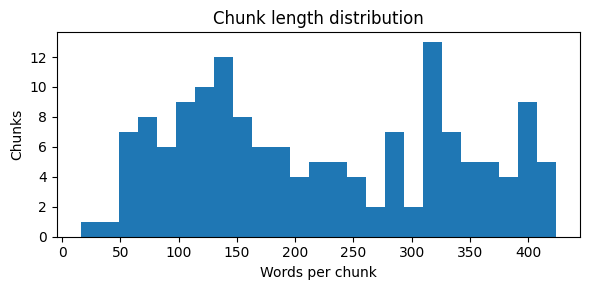

{'chunk_id': 'chunk_0086', 'pages': '71', 'page_start': '71', 'page_end': '71', 'chapter': 'Recommendations and Evidence Summaries', 'question': '4', 'question_title': 'Should oral rehydration solution (ORS) be given to patients with mild dengue or dengue without warning signs to prevent disease progression?', 'section': 'RECOMMENDATION', 'n_words': 54}
Question 4: Should oral rehydration solution (ORS) be given to patients with mild dengue or dengue without warning signs to prevent disease progression? | Section: RECOMMENDATION
Recommendation: Among patients with probable or confirmed dengue fever, we recommend the use of oral rehydration solution to prevent poor outcomes. (Very low certainty of evidence, Strong recommendation)


In [10]:
# Chunk length distribution and one example chunk
import matplotlib.pyplot as plt
lengths = [c["n_words"] for c in chunks]
plt.figure(figsize=(6, 3))
plt.hist(lengths, bins=25)
plt.xlabel("Words per chunk"); plt.ylabel("Chunks"); plt.title("Chunk length distribution")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "chunk_lengths.png", dpi=150); plt.show()

example = next(c for c in chunks if c["question"] == "4" and c["section"] == "RECOMMENDATION")
print({k: v for k, v in example.items() if k != "text"})
print(example["text"])

### 2.3 Embedding and indexing
`BAAI/bge-m3` turns each chunk into a dense vector. The same model embeds the user question at query time. Vectors and metadata are stored in a persistent **Chroma** collection with cosine distance. Metadata (pages, question, section) is stored but not embedded, since the section header is already part of the chunk text.

*Fill in after running:*

| Item | Value |
|---|---|
| Number of chunks | |
| Mean / max chunk length (words) | |
| Embedding dimension | |
| Index build time (s) | |

Source code: `src/index.py` (from the GitHub repo). Run the cell to display it.

In [11]:
show("src/index.py")

"""
Step 2 of the indexing pipeline: chunks -> BGE-M3 embeddings -> persistent Chroma collection.

The collection uses cosine distance. LlamaIndex reports a score of exp(-distance),
so retrieval code converts it back to cosine similarity with 1 + ln(score).
"""
import math

import chromadb
from llama_index.core import StorageContext, VectorStoreIndex
from llama_index.core.schema import TextNode
from llama_index.vector_stores.chroma import ChromaVectorStore

from .config import CONFIG, CHROMA_DIR

META_KEYS = ["pages", "page_start", "page_end", "chapter", "question",
             "question_title", "section", "n_words"]


def get_embed_model(device=None):
    """Load BGE-M3 through the LlamaIndex Hugging Face integration (downloads ~2.3 GB once)."""
    from llama_index.embeddings.huggingface import HuggingFaceEmbedding
    return HuggingFaceEmbedding(
        model_name=CONFIG["embed_model"],
        max_length=CONFIG["embed_max_length"],
        embed_batch_size=16,
        normalize=T

In [12]:
import time
from src.index import get_embed_model, build_index, load_index

embed_model = get_embed_model()
print("Embedding dimension:", len(embed_model.get_text_embedding("dengue")))

start = time.time()
index, collection = build_index(chunks, embed_model, rebuild=True)
print(f"Indexed {collection.count()} chunks in {time.time() - start:.1f} s")

# Later sessions: skip build_index and use
# index = load_index(embed_model)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Embedding dimension: 1024


Generating embeddings:   0%|          | 0/151 [00:00<?, ?it/s]

Indexed 151 chunks in 22.7 s


## 3. Requirements

| Category | Library / tool | Use |
|---|---|---|
| LLM framework | `llama-index-core` | Nodes, vector index, retriever |
| Integrations | `llama-index-vector-stores-chroma`, `llama-index-embeddings-huggingface` | Chroma store, BGE-M3 |
| Vector database | `chromadb` | Persistent vector store (cosine) |
| Embedding model | `BAAI/bge-m3` | Dense embeddings |
| LLM A | `Qwen/Qwen3-8B` | Generator (thinking mode off) |
| LLM B | `google/gemma-3-12b-it` | Generator |
| Model runtime | `transformers`, `accelerate`, `bitsandbytes`, `torch` | 4-bit NF4 loading and generation |
| PDF loader | `pymupdf` | Text, table and superscript extraction |
| Evaluation | `pandas`, `numpy`, `matplotlib` | Metrics and plots |
| LLM judge (optional) | `google-genai` (Gemini Flash) | Faithfulness scoring |
| UI | `streamlit`, `cloudflared` | Web app and public tunnel from Colab |
| Hardware | Google Colab T4 GPU (16 GB) | Inference |

Exact versions used are printed below. Copy them into the paper.

In [13]:
from importlib.metadata import version
for pkg in ["torch", "transformers", "accelerate", "bitsandbytes", "llama-index-core",
            "llama-index-vector-stores-chroma", "llama-index-embeddings-huggingface",
            "chromadb", "pymupdf", "streamlit", "google-genai", "pandas"]:
    try:
        print(f"{pkg:38s} {version(pkg)}")
    except Exception:
        print(f"{pkg:38s} not installed")

torch                                  2.14.1+cu130
transformers                           5.22.1
accelerate                             1.15.0
bitsandbytes                           0.50.2
llama-index-core                       0.14.26
llama-index-vector-stores-chroma       0.7.0
llama-index-embeddings-huggingface     0.9.0
chromadb                               1.5.9
pymupdf                                2.1
streamlit                              1.67.0
google-genai                           2.12.1
pandas                                 2.2.3


## 4. System Architecture

### 4.1 Overview

**Indexing pipeline (run once):** PDF → cleaning → section-aware chunking with metadata → BGE-M3 embeddings → Chroma.

**Query pipeline (every question):** question → input check → BGE-M3 query embedding → similarity search (top-4) → cutoff check → prompt with numbered excerpts and page labels → LLM (Qwen3-8B or Gemma 3 12B) → answer with page citations.

*Insert the system flow diagram image here.*

```
function ANSWER(question, llm):
    if question is empty or too long: return input error message
    hits ← top_k chunks by cosine similarity to embed(question)
    used ← [h in hits where h.score ≥ cutoff]
    if used is empty: return REFUSAL                      (no LLM call)
    prompt ← SYSTEM_RULES + excerpts(used, page labels) + question
    return llm.generate(prompt), used, latency
```

### 4.2 Prompt design and grounding
- The system prompt limits the LLM to the excerpts and requires a page citation after each statement.
- Recommendation strength and certainty of evidence must be stated as written.
- A fixed refusal sentence is used when the excerpts do not answer the question. The same sentence is returned without an LLM call when no chunk passes the similarity cutoff.
- Answers follow the question's language (English or Filipino) and keep medical terms in English.
- Greedy decoding removes randomness so both models are compared fairly.

Source code: `src/rag.py` (from the GitHub repo). Run the cell to display it.

In [14]:
show("src/rag.py")

"""
Query pipeline: question -> retrieve top-k chunks -> cutoff check -> grounded prompt -> LLM answer.
"""
import time

from .config import CONFIG
from .index import score_to_cosine

REFUSAL = "This question is not covered by the DOH Dengue Clinical Practice Guideline (2023)."

# Prompt versions are tracked in runs/README.md. v1 was used up to Run 03.
# v2 targets issues I-04 to I-09 found on the development set (rules 1-5 and 8).
PROMPT_VERSION = "v2"

SYSTEM_PROMPT = f"""You are Denguide, an assistant for Filipino primary care providers.
You answer questions using only the excerpts from the DOH Clinical Practice Guideline on Dengue (2023) given in the user message.

Rules:
1. Use only facts stated in the excerpts. Do not add outside medical knowledge or your own explanations.
2. End every sentence with a citation in the form (CPG p. X). Use only the page numbers shown in the excerpt labels.
3. Write about the guideline in the third person, for example "The CPG recommends" or "The CP

Evaluation helpers (retrieval metrics, cutoff tuning, full runs, judge, ratings). Used here for cutoff tuning and in Section 5.

Source code: `src/evaluate.py` (from the GitHub repo). Run the cell to display it.

In [15]:
show("src/evaluate.py")

"""
Evaluation on the development and unseen question sets.

Question CSV columns
    id, question, type, reference_answer, gold_pages, in_scope
    gold_pages: printed CPG page numbers separated by ";" (empty for out-of-scope questions)
    in_scope:   1 if the guideline answers it, 0 if not

Metrics
    Retrieval precision@k, recall@k (hit rate), MRR   - from gold_pages, before the cutoff
    Refusal accuracy                                  - out-of-scope refused, in-scope answered
    Citation accuracy                                 - cited pages that were among the excerpts given
    Faithfulness                                      - optional Gemini judge on answered questions
    Latency                                           - seconds per question
"""
import hashlib
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd

from .config import CONFIG
from .rag import PROMPT_VERSION


# ------------------------------------------------

In [16]:
from src.rag import DenguideRAG, build_messages, SYSTEM_PROMPT
from src import evaluate as ev

rag = DenguideRAG(index)

# Retrieval check on one question
for h in rag.retrieve("Should ORS be given to patients with probable dengue?"):
    print(f"{h['score']:.3f} | p. {h['pages']:8s} | Q{h['question']:3s} | {h['section']}")

0.725 | p. 71       | Q4   | CONSIDERATIONS DURING THE CONSENSUS PANEL MEETING
0.724 | p. 71       | Q4   | RECOMMENDATION
0.712 | p. 71       | Q4   | KEY FINDINGS
0.706 | p. 75       | Q4   | RECOMMENDATIONS FROM OTHER GROUPS


### 4.3 Tuning the similarity cutoff (development set only)
The cutoff decides when the bot refuses. It is chosen from the top retrieval score of each **development** question so that in-scope questions pass and out-of-scope questions are refused. The unseen set is not used here.

,id,type,in_scope,top_score,retrieved_pages
0,d01,recommendation,1,0.7846,"26 | 33,34 | 28 | 32"
1,d02,numeric_table,1,0.6693,"26,27 | 28,29 | 34 | 32"
2,d03,recommendation,1,0.6259,"33,34 | 26 | 40 | 45,46"
3,d04,recommendation,1,0.7646,"52 | 53,54 | 59,60 | 62"
4,d05,recommendation,1,0.7229,"64 | 64,65 | 66 | 68"
5,d06,recommendation,1,0.7251,71 | 71 | 71 | 75
6,d07,recommendation,1,0.7812,84 | 79 | 84 | 86
7,d08,herbal,1,0.7231,98 | 96 | 90 | 91
8,d09,prevention,1,0.7663,"103 | 105,106 | 102 | 104,105"
9,d10,numeric_table,1,0.6789,"27,28 | 5 | 1 | 6"


Dev retrieval: {'precision@4': np.float64(0.379), 'recall@4': np.float64(0.931), 'mrr': np.float64(0.759), 'n_in_scope': 29}
Best cutoff on dev set: 0.61


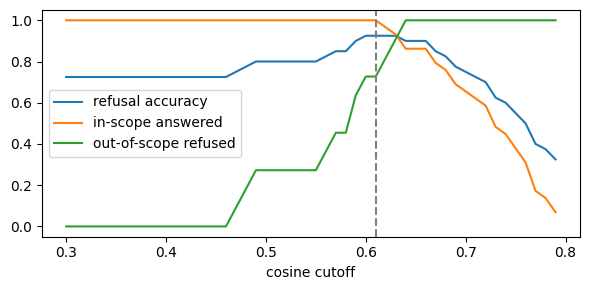

In [17]:
import matplotlib.pyplot as plt
dev = ev.load_questions(DEV_QUESTIONS)
dev_retrieval = ev.retrieval_table(rag, dev)
display(dev_retrieval[["id", "type", "in_scope", "top_score", "retrieved_pages"]])
print("Dev retrieval:", ev.retrieval_metrics(dev_retrieval))

best_cutoff, curve = ev.tune_cutoff(dev_retrieval)
print("Best cutoff on dev set:", best_cutoff)
save_override(sim_cutoff=best_cutoff)     # saved to Drive; the app reads it too
rag.cutoff = best_cutoff

plt.figure(figsize=(6, 3))
plt.plot(curve["cutoff"], curve["refusal_accuracy"], label="refusal accuracy")
plt.plot(curve["cutoff"], curve["in_scope_kept"], label="in-scope answered")
plt.plot(curve["cutoff"], curve["out_scope_refused"], label="out-of-scope refused")
plt.axvline(best_cutoff, ls="--", c="gray"); plt.xlabel("cosine cutoff"); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR / "cutoff_tuning.png", dpi=150); plt.show()

### 4.4 Loading the two LLMs
Both models load from Hugging Face in 4-bit NF4. Only one stays on the GPU at a time. `smoke_test()` confirms the output is readable. If Gemma prints an empty or odd reply on the T4, set `CONFIG["compute_dtype"]["Gemma 3 12B"] = "float32"` and load it again.

Source code: `src/llm.py` (from the GitHub repo). Run the cell to display it.

In [18]:
show("src/llm.py")

"""
Local LLM wrapper for the two compared generators (Qwen3-8B and Gemma 3 12B-IT).

Both models are loaded from Hugging Face in 4-bit NF4 so they fit on a free Colab T4 GPU.
Only one model should be on the GPU at a time: call unload() before loading the other.
"""
import gc
import re
import threading

import torch
from transformers import (AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig,
                          TextIteratorStreamer)

from .config import CONFIG

THINK_BLOCK = re.compile(r"<think>.*?</think>", re.DOTALL)


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def pick_dtype(name):
    """Choose the compute dtype for one model (see CONFIG["compute_dtype"])."""
    choice = CONFIG["compute_dtype"].get(name, "auto")
    if choice != "auto":
        return getattr(torch, choice)
    if torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8:
        return torch.bfloat16          # Ampere or newer (

In [19]:
from src.llm import LocalLLM, free_gpu, gpu_memory_gb

llm = LocalLLM("Qwen3-8B")
print("GPU memory used (GB):", gpu_memory_gb())
llm.smoke_test()
rag.llm = llm

q = "Should ORS be given to patients with probable dengue?"
res = rag.answer(q)
print(res["answer"]); print("latency:", res["latency_s"], "s | pages used:", [h["pages"] for h in res["used"]])

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

GPU memory used (GB): 7.79
Qwen3-8B (float16): 'OK' -> looks fine
The CPG recommends the use of oral rehydration solution (ORS) to prevent poor outcomes in patients with probable or confirmed dengue fever (Very low certainty of evidence, Strong recommendation) (CPG p. 71). The panel emphasized that ORS is strongly recommended for hydration due to its potential to prevent disease progression, low cost, acceptability, accessibility, and feasibility of implementation at the community level (CPG p. 71). Additionally, the CPG notes that ORS is preferable to plain water for fluid and electrolyte therapy in patients with excessive sweating or vomiting (CPG p. 75).
latency: 10.86 s | pages used: ['71', '71', '71', '75']


In [20]:
# The exact prompt sent to the LLM (for the report)
print(build_messages(q, res["used"])[1]["content"][:2000])

Guideline excerpts:

[Excerpt 1 | CPG p. 71]
Question 4: Should oral rehydration solution (ORS) be given to patients with mild dengue or dengue without warning signs to prevent disease progression? | Section: CONSIDERATIONS DURING THE CONSENSUS PANEL MEETING
Based on evidence alone, there was a weak strength of recommendation because of the very low certainty of evidence regarding the effectiveness of oral rehydration. However, the panel decided to strongly recommend ORS for hydration of patients with mild dengue infections because of its potential to prevent disease progression to critical phase and poor outcomes, cheap cost, acceptability to most clinicians taking care of dengue, accessibility, and feasibility of implementation at the community level, with low anticipated related adverse events. It was also emphasized that the absence of evidence neither means it is not beneficial nor does it equate to harm.

[Excerpt 2 | CPG p. 71]
Question 4: Should oral rehydration solution (ORS) 

In [21]:
# Development run for Qwen3-8B (tuning evidence only)
dev_runs = {}
dev_runs["Qwen3-8B"] = ev.run_questions(rag, dev, "Qwen3-8B", RESULTS_DIR / "dev_qwen3-8b.csv")

   d01 | 15.16s | refused=False | 'The CPG recommends the use of dengue NS1 rapid diagnostic test among t'
   d02 | 13.31s | refused=False | 'The pooled sensitivity of NS1 rapid diagnostic tests (RDTs) was 0.70 ('
   d03 |  6.62s | refused=False | 'For a patient who consults more than 5 days after symptom onset, the C'
   d04 |  8.69s | refused=False | 'The CPG recommends using any one of the following clinical signs as a '
   d05 | 10.64s | refused=False | 'The CPG suggests that daily CBC determination may be done as part of d'
   d06 | 11.83s | refused=False | 'The CPG recommends the use of oral rehydration solution (ORS) to preve'
   d07 |   7.7s | refused=False | 'The CPG recommends against the use of acid suppressants for the preven'
   d08 | 11.67s | refused=False | 'The CPG recommends against giving tawa-tawa (Euphorbia hirta) preparat'
   d09 |  10.8s | refused=False | 'The CPG suggests against the use of non-DEET plant-based repellents ov'
   d10 |  4.63s | refused=False | 'In

In [22]:
# Switch to Gemma 3 12B: unload Qwen first
if "llm" in globals():
    llm.unload(); del llm
rag.llm = None; free_gpu()
print("GPU memory after unload (GB):", gpu_memory_gb())

llm = LocalLLM("Gemma 3 12B")
print("GPU memory used (GB):", gpu_memory_gb())
llm.smoke_test()
rag.llm = llm
dev_runs["Gemma 3 12B"] = ev.run_questions(rag, dev, "Gemma 3 12B", RESULTS_DIR / "dev_gemma3-12b.csv")
ev.summarize(dev_runs)

GPU memory after unload (GB): 2.12


Loading weights:   0%|          | 0/1065 [00:00<?, ?it/s]

GPU memory used (GB): 11.28
Gemma 3 12B (float32): 'OK' -> looks fine
   d01 | 36.78s | refused=False | 'The CPG recommends the use of dengue NS1 rapid diagnostic test among t'
   d02 | 43.57s | refused=False | 'The CPG states that pooled analysis of the 11 studies showed that RDTs'
   d03 | 25.59s | refused=False | 'The CPG recommends the use of a rapid diagnostic test with dengue IgM/'
   d04 |  27.8s | refused=False | 'The CPG recommends using any one of the following clinical signs as a '
   d05 | 33.47s | refused=False | 'The CPG suggests an initial CBC should be requested on the first visit'
   d06 | 28.95s | refused=False | 'The CPG recommends the use of oral rehydration solution to prevent poo'
   d07 |  28.7s | refused=False | 'The CPG recommends against the use of acid suppressants for the preven'
   d08 | 23.04s | refused=False | 'The CPG suggests against giving tawa-tawa (Euphorbia hirta) preparatio'
   d09 | 35.03s | refused=False | 'The CPG suggests against the use of pla

OutOfMemoryError: CUDA out of memory. Tried to allocate 154.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 89.81 MiB is free. Including non-PyTorch memory, this process has 14.47 GiB memory in use. Of the allocated memory 13.63 GiB is allocated by PyTorch, and 726.57 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [23]:
llm.unload(); del llm; rag.llm = None; free_gpu()

## 5. System Evaluation (Unseen Queries)

### 5.1 Question sets and leakage avoidance

| Set | Size | Used for | File |
|---|---|---|---|
| Development | 15 questions | Cutoff tuning and prompt checks | `eval/dev/dev_questions.csv` |
| Unseen (held-out) | about 40 questions | Final evaluation only | `MyDrive/Denguide_work/eval/unseen/unseen_questions.csv` (private, in GitHub only after the final run) |

Suggested unseen composition: 15 recommendation lookups, 8 table or numeric questions, 7 prevention or herbal questions, 5 out-of-scope questions, 5 Taglish questions. Columns: `id, type, question, reference_answer, gold_pages, in_scope` (see `eval/unseen/unseen_questions_TEMPLATE.csv`). Gold pages use the printed page numbers.

**Leakage controls:**
- One member writes the unseen set from the CPG before tuning starts, and the members who tune do not open it.
- The SHA-256 hash of the file is recorded below when it is created and checked again before the final run.
- All settings are frozen in `results/config.json` before the unseen run.

| Unseen set SHA-256 | Date created | Created by |
|e7baf3a48cb94f559d4467fc75410836f546c7c23ed2ac9eaeb400bb1ae88c11 |2026-11-25|Adrian Ivan Aldea|
| | | |

In [27]:
# Run once when the unseen file is created; paste the hash into the table above.
from src.config import save_config, load_frozen_config
print("SHA-256:", ev.file_sha256(UNSEEN_QUESTIONS))

SHA-256: e7baf3a48cb94f559d4467fc75410836f546c7c23ed2ac9eaeb400bb1ae88c11


In [ ]:
# Before the final run: verify the file is unchanged and freeze the settings.
RECORDED_HASH = "paste-the-hash-from-the-table-here"
assert ev.file_sha256(UNSEEN_QUESTIONS) == RECORDED_HASH, "Unseen file changed since it was recorded!"
save_config()
print("Frozen config:", load_frozen_config())
unseen = ev.load_questions(UNSEEN_QUESTIONS)
unseen["type"].value_counts()

### 5.2 Metrics

| Metric | Definition |
|---|---|
| Retrieval precision@4 | Share of the 4 retrieved chunks that come from a gold page |
| Retrieval recall@4 (hit rate) | Share of in-scope questions with at least one gold page retrieved |
| MRR | Mean of 1 / rank of the first gold-page chunk |
| Refusal accuracy | Out-of-scope refused plus in-scope answered, over all questions |
| Faithfulness | Supported claims / total claims, judged by Gemini Flash against the excerpts used |
| Correctness | Mean of two members' blind 1 to 5 ratings against the reference answer |
| Latency | Seconds per question, mean and median |

Retrieval is identical for both models, so the retrieval metrics match. The judge is not one of the compared models.

In [ ]:
# Final unseen run, one model at a time
unseen_runs = {}
for name, fname in [("Qwen3-8B", "unseen_qwen3-8b.csv"), ("Gemma 3 12B", "unseen_gemma3-12b.csv")]:
    llm = LocalLLM(name); llm.smoke_test(); rag.llm = llm
    unseen_runs[name] = ev.run_questions(rag, unseen, name, RESULTS_DIR / fname)
    llm.unload(); del llm; rag.llm = None; free_gpu()
ev.summarize(unseen_runs)

In [ ]:
# Optional: faithfulness judge (needs GEMINI_API_KEY in Colab Secrets; free tier is slow)
key = userdata.get("GEMINI_API_KEY")
for name in unseen_runs:
    unseen_runs[name] = ev.judge_faithfulness(unseen_runs[name], api_key=key)
    unseen_runs[name].to_csv(RESULTS_DIR / f"unseen_{name.replace(' ', '_').lower()}_judged.csv", index=False)

In [ ]:
# Manual correctness: export a blind sheet, two members rate 1-5, then load it back
sheet = ev.export_rating_sheet(unseen_runs, RESULTS_DIR / "ratings.csv")
print("Rate the answers in results/ratings.csv (columns rater1_1to5, rater2_1to5), then run the next cell.")
print("Sorting the sheet is fine. Keep the row column unchanged.")

In [ ]:
for name in unseen_runs:
    unseen_runs[name] = ev.attach_ratings(unseen_runs[name], name, RESULTS_DIR / "ratings.csv")
summary = ev.summarize(unseen_runs)
summary.to_csv(RESULTS_DIR / "summary_unseen.csv", index=False)
summary.T

### 5.3 Hallucination handling and failure cases
The cell below lists every in-scope question refused, every out-of-scope question answered, every retrieval miss, and every answer with unsupported claims. For each case, note the cause: retrieval miss, table extraction, outside knowledge added by the LLM, or a language issue.

In [ ]:
import pandas as pd
pd.set_option("display.max_colwidth", 120)
for name, df in unseen_runs.items():
    print(f"===== {name}")
    wrong_refusal = df[(df.in_scope == 1) & df.refused]
    answered_oos = df[(df.in_scope == 0) & ~df.refused]
    missed = df[(df.in_scope == 1) & ~df.relevant_flags.apply(any)]
    unfaithful = df[df.get("faithfulness", pd.Series(1.0, index=df.index)) < 1.0]
    for label, part in [("In-scope refused", wrong_refusal), ("Out-of-scope answered", answered_oos),
                        ("Retrieval missed gold page", missed), ("Unsupported claims", unfaithful)]:
        print(f"\n{label}: {len(part)}")
        if len(part):
            display(part[["id", "question", "answer", "used_pages"]])

### 5.4 Retrieved context vs generated answers

In [ ]:
side = unseen_runs["Qwen3-8B"][["id", "question", "used_pages", "context", "answer"]].rename(columns={"answer": "Qwen3-8B"})
side = side.merge(unseen_runs["Gemma 3 12B"][["id", "answer"]].rename(columns={"answer": "Gemma 3 12B"}), on="id")
for _, row in side.head(3).iterrows():
    print(f"Q: {row['question']}\nPages used: {row['used_pages']}\n--- Context (start)\n{str(row['context'])[:600]}\n"
          f"--- Qwen3-8B\n{row['Qwen3-8B']}\n--- Gemma 3 12B\n{row['Gemma 3 12B']}\n{'=' * 80}")

## 6. Web Deployment

`app.py` is a Streamlit chat app built on the same `src` modules.

**Features:** question box, model selector (Qwen3-8B, Gemma 3 12B, or retrieval only), streamed answers, an expandable source panel with pages and similarity scores, latency per answer, and a clinician disclaimer.

**Error handling:**

| Case | App behaviour |
|---|---|
| Empty or whitespace question | Warning, no model call |
| Question over 500 characters | Warning with the limit |
| No chunk above the cutoff | Fixed refusal sentence, closest excerpts shown, no model call |
| Model, GPU or index error | Friendly error message; details written to `logs/app.log` |
| First model load | Spinner with status text |
| No GPU available | "Retrieval only" mode still answers with excerpts |

**Running from Colab.** The app runs in its own process and loads its own model copy, so free the notebook's GPU memory first (or restart the runtime and run only Section 0 and this section). The tuned cutoff is read from `settings_override.json` in the Drive work folder. A Cloudflare quick tunnel gives a public `trycloudflare.com` link for the demo.

Source code: `app.py` (from the GitHub repo). Run the cell to display it.

In [ ]:
show("app.py")

In [ ]:
# Free the notebook's GPU memory before starting the app
from src.llm import free_gpu       # imported here too, so this works after Section 0 only
if "llm" in globals():
    llm.unload(); del llm
free_gpu()
print("Cutoff the app will use:", CONFIG["sim_cutoff"])

In [ ]:
!pkill -f "streamlit run" ; pkill -f cloudflared ; sleep 1
!nohup streamlit run app.py --server.port 8501 --server.headless true > {WORK}/logs/streamlit.log 2>&1 &
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared
!nohup /content/cloudflared tunnel --url http://localhost:8501 > {WORK}/logs/tunnel.log 2>&1 &

import time, re
time.sleep(10)
urls = re.findall(r"https://[\w-]+\.trycloudflare\.com", open(f"{WORK}/logs/tunnel.log").read())
print("Open the app at:", urls[0] if urls else "not ready yet, run this cell again")

*Insert screenshots: home screen, answered question with sources, out-of-scope refusal, empty-input warning, retrieval-only mode.*

## 7. Results and Analysis

### 7.1 Sample interactions
Show 5 representative Q&A pairs per model (include one refusal and one Taglish question).

In [ ]:
for name, df in unseen_runs.items():
    print(f"===== {name}")
    picks = pd.concat([df[df.type == t].head(1) for t in df.type.unique()])
    for r in picks.itertuples():
        print(f"[{r.type}] Q: {r.question}\nA: {r.answer}\n")

### 7.2 Quantitative comparison

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
metrics = [c for c in ["refusal_accuracy", "faithfulness_mean", "correctness_mean_1to5",
                       "latency_mean_s"] if c in summary]
fig, axes = plt.subplots(1, len(metrics), figsize=(3.2 * len(metrics), 3))
for ax, m in zip(np.atleast_1d(axes), metrics):
    ax.bar(summary["model"], summary[m], color=["#4C72B0", "#DD8452"])
    ax.set_title(m); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=150); plt.show()

if "faithfulness" in unseen_runs["Qwen3-8B"]:
    by_type = pd.concat({n: d.groupby("type")["faithfulness"].mean() for n, d in unseen_runs.items()}, axis=1)
    by_type.plot.bar(figsize=(7, 3), title="Faithfulness by question type"); plt.tight_layout()
    plt.savefig(RESULTS_DIR / "faithfulness_by_type.png", dpi=150); plt.show()

    # How retrieval quality affects answers
    for n, d in unseen_runs.items():
        plt.scatter(d["top_score"], d["faithfulness"], label=n, alpha=0.7)
    plt.axvline(CONFIG["sim_cutoff"], ls="--", c="gray"); plt.xlabel("top retrieval score (cosine)")
    plt.ylabel("faithfulness"); plt.legend(); plt.tight_layout()
    plt.savefig(RESULTS_DIR / "retrieval_vs_faithfulness.png", dpi=150); plt.show()

### 7.3 Discussion
*Write after the runs:*
- Which model stayed closer to the retrieved text, and on which question types?
- When retrieval missed the gold page, did either model still answer? This signals outside knowledge.
- How did table questions compare with prose questions?
- Did Taglish questions retrieve the right chunks?
- Is the extra size of Gemma 3 12B worth its latency and memory cost here?

## 8. Documentation (IEEE Format)

The paper is submitted separately as `.docx` in IEEE format: Abstract; Introduction; Methodology (knowledge base, pipeline, LLMs, deployment); Results and Discussion; Conclusion and Future Work; References (IEEE style). The model selection rationale is in `Denguide_LLM_Selection_Rationale.docx`.

## 9. Insights and Conclusions

*Write after Section 7:*
- What the group learned about building a RAG chatbot.
- Strengths of the system.
- Limitations: retrieval errors, table extraction, hallucinations, Filipino queries, a one-document corpus, GPU limits.
- Future work: reranking, hybrid (dense plus keyword) retrieval, better table parsing, adding the pediatric CPG, a medical-domain LLM such as MedGemma, and user testing with clinicians.

## 10. References

### 10.1 Scholarly articles (APA)
*Add one line under each on how the group used it. Check every entry against its source.*

- Department of Health. (2023). *Clinical practice guideline on the diagnosis, management and prevention of dengue for adult and pediatric Filipinos in the primary care setting.* Department of Health, Philippines.
  *Use:* knowledge base.
- Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474.
- Yang, A., et al. (2025). *Qwen3 technical report* (arXiv:2505.09388). arXiv. https://arxiv.org/abs/2505.09388
- Gemma Team. (2025). *Gemma 3 technical report* (arXiv:2503.19786). arXiv. https://arxiv.org/abs/2503.19786
- Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D., & Liu, Z. (2024). *BGE M3-Embedding: Multi-lingual, multi-functionality, multi-granularity text embeddings through self-knowledge distillation* (arXiv:2402.03216). arXiv. https://arxiv.org/abs/2402.03216
- Es, S., James, J., Espinosa-Anke, L., & Schockaert, S. (2024). RAGAS: Automated evaluation of retrieval augmented generation. In *Proceedings of the 18th Conference of the European Chapter of the Association for Computational Linguistics: System Demonstrations* (pp. 150–158).
- Xiong, G., Jin, Q., Lu, Z., & Zhang, A. (2024). Benchmarking retrieval-augmented generation for medicine. In *Findings of the Association for Computational Linguistics: ACL 2024*.
- Tamber, M. S., et al. (2025). Benchmarking LLM faithfulness in RAG with evolving leaderboards. In *Proceedings of EMNLP 2025: Industry Track*. https://arxiv.org/abs/2505.04847
- Miranda, L. J. V., Aco, E., Manuel, C. G., Cruz, J. C. B., & Imperial, J. M. (2025). FilBench: Can LLMs understand and generate Filipino? In *Proceedings of EMNLP 2025* (pp. 2496–2529).
- Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023). QLoRA: Efficient finetuning of quantized LLMs. *Advances in Neural Information Processing Systems, 36*.

### 10.2 Online references
| Title | Link | How we used it |
|---|---|---|
| LlamaIndex documentation | https://docs.llamaindex.ai | |
| Chroma documentation | https://docs.trychroma.com | |
| PyMuPDF documentation | https://pymupdf.readthedocs.io | |
| Qwen3-8B model card | https://huggingface.co/Qwen/Qwen3-8B | |
| Gemma 3 12B-IT model card | https://huggingface.co/google/gemma-3-12b-it | |
| BGE-M3 model card | https://huggingface.co/BAAI/bge-m3 | |
| Vectara hallucination leaderboard | https://github.com/vectara/hallucination-leaderboard | |
| Streamlit documentation | https://docs.streamlit.io | |
| Cloudflare quick tunnels | https://developers.cloudflare.com/cloudflare-one/connections/connect-networks/do-more-with-tunnels/trycloudflare/ | |

### 10.3 Artificial Intelligence (AI) tools
| Model | Transcript | How we used it |
|---|---|---|
| Claude (Anthropic), claude.ai chat. Model: *write the model name shown in the chat* | *Attach the full transcript of every chat* | Project scoping, dataset inspection, model selection research, notebook structure and markdown drafts, and the Python code in `src/` and `app.py`. The group reviewed, ran and adjusted the code. |
| Claude Opus 5.5 (Anthropic), Claude Code | *Attach the full transcript of every session* | GitHub repository setup, the `save_to_github` cell, a format check of the unseen set without reading its questions (gold pages changed from PDF to printed page numbers), a review of this notebook and fixes from that review. |
| *Add others used* | | |

## Save outputs to GitHub
Run at the end of every session. Describe the session in the message.

In [23]:
save_to_github("Run 05 (failed): Gemma out of memory at d16; Qwen complete on dev set v2")

Saved to GitHub: e051518 Run 05 (failed): Gemma out of memory at d16; Qwen complete on dev set v2

